In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

df = pd.read_csv("../raw/Social_media_impact_on_life.csv")
df = df.drop(columns=["Student_ID"])

X = df.drop(columns=["Overall_Impact"])
y = df["Overall_Impact"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

colunas_numericas = [
    "Daily_Usage_Hours",
    "Mental_Health_Index",
    "Perceived_Stress_Score",
    "Academic_Performance_GPA",
    "Sleep_Duration_Hours",
    "Sleep_Quality_Score"
]
colunas_categoricas = ["Primary_Platform"]

pipe_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

pipe_cat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessador = ColumnTransformer(
    transformers=[
        ("num", pipe_num, colunas_numericas),
        ("cat", pipe_cat, colunas_categoricas)
    ],
    remainder="drop"
)



In [2]:
modelos = {
    "0. Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "1. Regressão Logística (Balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "2. Random Forest (Balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "3. Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

for nome, clf in modelos.items():
    pipe = Pipeline(steps=[
        ("preprocessamento", preprocessador),
        ("modelo", clf)
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    resultados.append({
        "Modelo": nome,
        "F1-Macro Médio (CV)": round(scores.mean(), 4),
        "Desvio Padrão": round(scores.std(), 4)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="F1-Macro Médio (CV)", ascending=False)
display(df_resultados)

,Modelo,F1-Macro Médio (CV),Desvio Padrão
3,3. Gradient Boosting,0.9527,0.0184
1,1. Regressão Logística (Balanced),0.9346,0.0128
2,2. Random Forest (Balanced),0.9206,0.0181
0,0. Baseline (Dummy),0.3000,0.0002


F1-Macro Final no Teste: 0.9474

Relatório Detalhado por Classe:
              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99      1104
    Negative       0.92      0.94      0.93        50
     Neutral       0.94      0.90      0.92       196

    accuracy                           0.98      1350
   macro avg       0.95      0.95      0.95      1350
weighted avg       0.98      0.98      0.98      1350



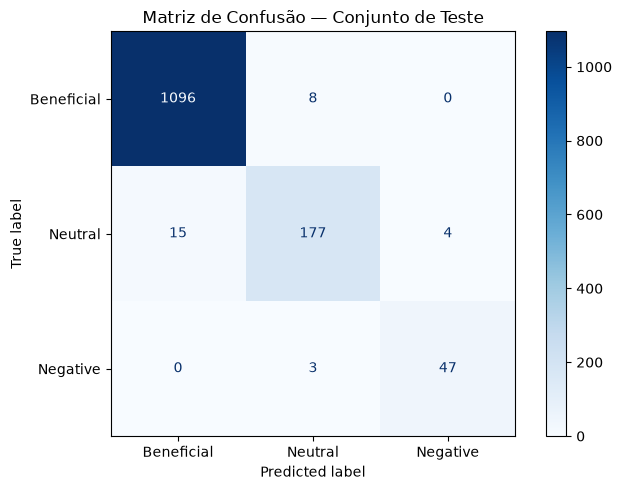

Artefato salvo com sucesso em: ..\models\pipeline.joblib


In [5]:
melhor_modelo = GradientBoostingClassifier(random_state=42)

pipeline_final = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("modelo", melhor_modelo)
])

# Treinar com todo o X_train e avaliar uma única vez no X_test
pipeline_final.fit(X_train, y_train)
y_pred = pipeline_final.predict(X_test)

print(f"F1-Macro Final no Teste: {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print("Relatório Detalhado por Classe:")
print(classification_report(y_test, y_pred))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["Beneficial", "Neutral", "Negative"],
    cmap="Blues",
    ax=ax
)
plt.title("Matriz de Confusão — Conjunto de Teste")
plt.tight_layout()
plt.show()

# Salvar o Pipeline completo (preprocessamento + modelo) para a Etapa 4
caminho_modelo = Path("../models/pipeline.joblib")
caminho_modelo.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline_final, caminho_modelo)
print(f"Artefato salvo com sucesso em: {caminho_modelo}")

**Interpretação da Matriz de Confusão:**

Alta assertividade na classe minoritária (Negative): Dos 50 estudantes com impacto negativo real no conjunto de teste, o modelo identificou corretamente 47 (94% de recall), errando apenas 3 para a classe vizinha (Neutral).   

Ausência de erros críticos: Os zeros nos cantos superior direito e inferior esquerdo da matriz provam que o modelo jamais confundiu extremos (nunca classificou um estudante com impacto negativo severo como benéfico, nem vice-versa).

Natureza dos erros: Os poucos erros ocorridos (30 no total de 1.350 amostras) concentram-se exclusivamente na fronteira entre a classe Neutral e suas vizinhas, o que é esperado em variáveis comportamentais contínuas.   